In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score,precision_score,recall_score,f1_score


In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [5]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['number_of_courses_viewed', 'annual_income', 'interaction_count', 'lead_score']
target=['converted']

In [6]:
for col in categorical:
    df[col]=df[col].fillna('NA')

In [7]:
for col in numerical:
    df[col] = df[col].fillna(0.0)
    

In [8]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [9]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)


y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [10]:
print('Training set size:', len(df_train))
print('Validation set size:', len(df_val))
print('Test set size:', len(df_test))

Training set size: 3000
Validation set size: 1000
Test set size: 1000


In [11]:
df_train.head()



,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score
0,paid_ads,technology,employed,asia,80198.0,5,9,0.91
1,paid_ads,retail,employed,asia,50548.0,2,5,0.48
2,NA,finance,employed,NA,76300.0,0,3,0.42
3,paid_ads,finance,employed,NA,80371.0,2,6,0.49
4,organic_search,finance,employed,asia,73567.0,2,4,0.48


In [12]:
y_train

array([1, 0, 0, ..., 0, 1, 1], shape=(3000,))

# Question 1: ROC AUC feature importance

In [13]:
variables = ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']
auc_scores = {}

for var in variables:
    score = df_train[var]
    
    auc = roc_auc_score(y_train, score)
    
    if auc < 0.5:
        auc = roc_auc_score(y_train, -score)
        print(f"{var}: {auc:.4f} (inverted)")
    else:
        print(f"{var}: {auc:.4f}")
        
    auc_scores[var] = auc

best_var = max(auc_scores.items(), key=lambda x: x[1])
print(f"\nHighest AUC: {best_var[0]} ({best_var[1]:.4f})")

lead_score: 0.7882
number_of_courses_viewed: 0.7230
interaction_count: 0.7649
annual_income: 0.6082

Highest AUC: lead_score (0.7882)


# Question 2: Training the model

In [14]:
def train(df_train,y_train,C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model

def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [15]:
dv, model = train(df_train, y_train, C=1.0)

In [16]:
y_val_pred = predict(df_val, dv, model)
y_val_pred

array([0.54472295, 0.79005207, 0.50977909, 0.52913949, 0.82072027,
       0.54246   , 0.50178717, 0.54698398, 0.82553299, 0.40583754,
       0.91301567, 0.33581825, 0.30789883, 0.42704803, 0.6219229 ,
       0.53665458, 0.41931937, 0.84087345, 0.79969125, 0.61790114,
       0.61625181, 0.68059931, 0.85605897, 0.8078487 , 0.62046017,
       0.45970722, 0.54556724, 0.41221393, 0.72714023, 0.46812079,
       0.77222191, 0.79043883, 0.61433884, 0.78549759, 0.49753426,
       0.66077291, 0.69804763, 0.76896543, 0.65657501, 0.64127911,
       0.66509115, 0.57942826, 0.67830946, 0.61186114, 0.86890227,
       0.4146967 , 0.84130129, 0.74229365, 0.68028539, 0.7189143 ,
       0.86417929, 0.64043375, 0.5424699 , 0.70225152, 0.27894903,
       0.70826494, 0.62310718, 0.47781771, 0.37914032, 0.69936035,
       0.52032869, 0.69977698, 0.75148939, 0.58087503, 0.47001802,
       0.56863492, 0.91297185, 0.79972028, 0.82206546, 0.36140197,
       0.66132404, 0.52330065, 0.79295471, 0.72068083, 0.71234

In [17]:
auc_score = roc_auc_score(y_val, y_val_pred)
print(f'Validation AUC: {auc_score}')

Validation AUC: 0.7318222288173319


# Question 3: Precision and Recall

In [18]:
thresholds = np.arange(0.0, 1.01, 0.01)
precisions = []
recalls = []

for t in thresholds:
    y_pred = (y_val_pred >= t).astype(int)
    p = precision_score(y_val, y_pred, zero_division=0)
    r = recall_score(y_val, y_pred, zero_division=0)
    precisions.append(p)
    recalls.append(r)

precisions = np.array(precisions)
recalls = np.array(recalls)

mask = (precisions > 0.1) & (recalls > 0.1)
valid_thresholds = thresholds[mask]
valid_precisions = precisions[mask]
valid_recalls = recalls[mask]

intersection_idx = np.argmin(np.abs(valid_precisions - valid_recalls))
intersection_threshold = valid_thresholds[intersection_idx]
intersection_value = valid_precisions[intersection_idx]

In [19]:
print(f"Threshold (x) = {intersection_threshold:.3f}")
print(f"Precision = Recall (y) = {intersection_value:.3f}")
print(f"Point = ({intersection_threshold:.3f}, {intersection_value:.3f})")

Threshold (x) = 0.630
Precision = Recall (y) = 0.733
Point = (0.630, 0.733)


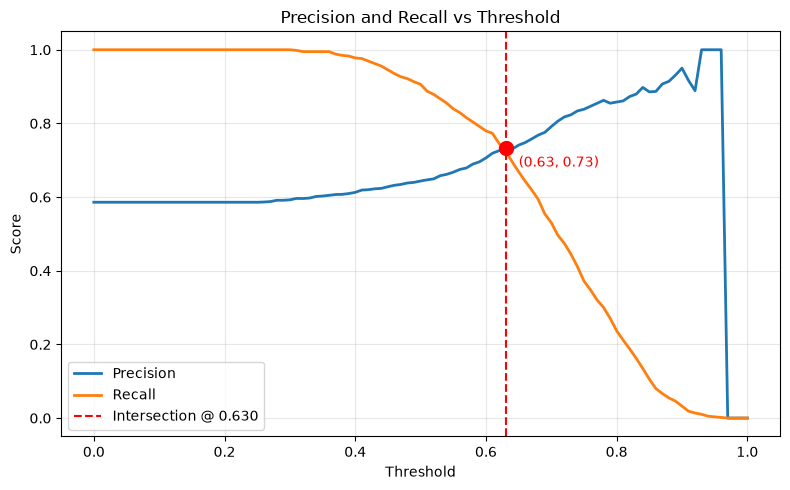

In [20]:
plt.figure(figsize=(8,5))
plt.plot(thresholds, precisions, label='Precision', linewidth=2)
plt.plot(thresholds, recalls, label='Recall', linewidth=2)

plt.axvline(intersection_threshold, color='red', linestyle='--', label=f'Intersection @ {intersection_threshold:.3f}')
plt.scatter(intersection_threshold, intersection_value, color='red', s=100, zorder=5)
plt.text(intersection_threshold + 0.02, intersection_value - 0.05,
         f"({intersection_threshold:.2f}, {intersection_value:.2f})",
         color='red', fontsize=10)

plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Threshold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Question 4: F1 score

In [22]:
thresholds = np.arange(0, 1.01, 0.01)

f1_scores = []

for threshold in thresholds:
    y_pred = (y_val_pred >= threshold).astype(int)
    
    f1 = f1_score(y_val, y_pred)
    f1_scores.append(f1)

f1_scores = np.array(f1_scores)

max_f1_idx = np.argmax(f1_scores)
max_f1_threshold = thresholds[max_f1_idx]
max_f1_score = f1_scores[max_f1_idx]

print(f"Maximum F1 score: {max_f1_score:.3f}")
print(f"Threshold (x) = {max_f1_threshold:.3f}")
print(f"Point = ({max_f1_threshold:.3f}, {max_f1_score:.3f})")

Maximum F1 score: 0.758
Threshold (x) = 0.410
Point = (0.410, 0.758)


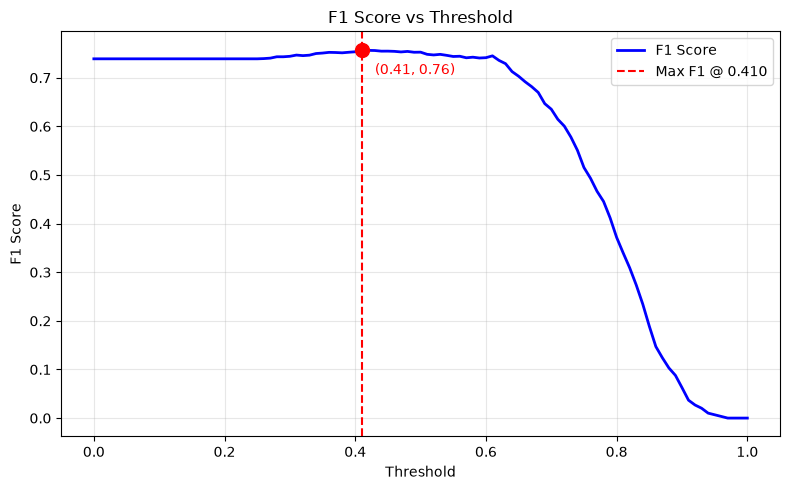

In [23]:
plt.figure(figsize=(8,5))
plt.plot(thresholds, f1_scores, label='F1 Score', linewidth=2, color='blue')

plt.axvline(max_f1_threshold, color='red', linestyle='--', label=f'Max F1 @ {max_f1_threshold:.3f}')
plt.scatter(max_f1_threshold, max_f1_score, color='red', s=100, zorder=5)
plt.text(max_f1_threshold + 0.02, max_f1_score - 0.05,
         f"({max_f1_threshold:.2f}, {max_f1_score:.2f})",
         color='red', fontsize=10)
plt.xlabel('Threshold')
plt.ylabel('F1 Score')
plt.title('F1 Score vs Threshold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Question 5: 5-Fold CV

In [24]:
def df_to_dict(df):
    return df.to_dict(orient='records')

kf = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for fold, (train_idx, val_idx) in enumerate(kf.split(df_full_train), 1):
    # Split the folds
    df_train_fold = df_full_train.iloc[train_idx]
    df_val_fold = df_full_train.iloc[val_idx]
    
    # Separate target variable
    y_train_fold = df_train_fold.converted.values
    y_val_fold = df_val_fold.converted.values
    
    # Remove target from features
    df_train_fold = df_train_fold.drop('converted', axis=1)
    df_val_fold = df_val_fold.drop('converted', axis=1)
    
    # One-hot encoding
    dv = DictVectorizer(sparse=False)
    X_train_fold = dv.fit_transform(df_to_dict(df_train_fold))
    X_val_fold = dv.transform(df_to_dict(df_val_fold))
    
    # Train Logistic Regression
    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train_fold, y_train_fold)
    
    # Predict and evaluate AUC
    y_pred_fold = model.predict_proba(X_val_fold)[:, 1]
    auc = roc_auc_score(y_val_fold, y_pred_fold)
    scores.append(auc)
    
    print(f"Fold {fold}: AUC = {auc:.3f}")

# Calculate mean and std
mean_auc = np.mean(scores)
std_auc = np.std(scores)

print("\n==============================")
print(f"Mean AUC: {mean_auc:.3f}")
print(f"Standard deviation: {std_auc:.6f}")
print("==============================")

Fold 1: AUC = 0.731
Fold 2: AUC = 0.730
Fold 3: AUC = 0.736
Fold 4: AUC = 0.741
Fold 5: AUC = 0.721

Mean AUC: 0.732
Standard deviation: 0.006853


# Question 6: Hyperparameter Tuning

In [26]:
c_values = [0.000001, 0.001, 1]
kf = KFold(n_splits=5, shuffle=True, random_state=1)
results = {}

for C in c_values:
    scores = []
    
    for fold, (train_idx, val_idx) in enumerate(kf.split(df_full_train), 1):
        # Split folds
        df_train_fold = df_full_train.iloc[train_idx]
        df_val_fold = df_full_train.iloc[val_idx]
        
        y_train_fold = df_train_fold.converted.values
        y_val_fold = df_val_fold.converted.values
        
        df_train_fold = df_train_fold.drop('converted', axis=1)
        df_val_fold = df_val_fold.drop('converted', axis=1)
        
        # One-hot encode with DictVectorizer
        dv = DictVectorizer(sparse=False)
        X_train_fold = dv.fit_transform(df_to_dict(df_train_fold))
        X_val_fold = dv.transform(df_to_dict(df_val_fold))
        
        # Train Logistic Regression
        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(X_train_fold, y_train_fold)
        
        # Predict and evaluate AUC
        y_pred_fold = model.predict_proba(X_val_fold)[:, 1]
        auc = roc_auc_score(y_val_fold, y_pred_fold)
        scores.append(auc)
    
    mean_auc = np.mean(scores)
    std_auc = np.std(scores)
    results[C] = {'mean': round(mean_auc, 3), 'std': round(std_auc, 3)}
    
    print(f"C={C}: mean AUC={mean_auc:.3f}, std={std_auc:.3f}")

best_C = sorted(results.items(), key=lambda x: (-x[1]['mean'], x[1]['std'], x[0]))[0]

print("\n==============================")
print(f"Best C value: {best_C[0]}")
print(f"Mean AUC: {best_C[1]['mean']:.3f} ± {best_C[1]['std']:.3f}")
print("==============================")

C=1e-06: mean AUC=0.617, std=0.019
C=0.001: mean AUC=0.749, std=0.010
C=1: mean AUC=0.732, std=0.007

Best C value: 0.001
Mean AUC: 0.749 ± 0.010
